# Avaliação automática da qualidade da aorta

Comparação descritiva de ImageCAS, MM-WHS e OrCaScore, em mid/high e por subconjunto.
“Adequada” significa ausência dos alertas definidos pelo pipeline, não confirmação anatômica nem acurácia.
As referências atuais e o histórico ImageCAS mid são apresentados separadamente.
Esta análise lê apenas CSVs existentes: não executa segmentação, não recalcula diagnósticos e não altera runs.

A avaliação visual externa, o Dice do MM-WHS e a inspeção 3D estão em
[Avaliação externa da aorta](../results/external_aorta_assessment.ipynb).

In [1]:
# ruff: noqa: E402
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from ipywidgets import BoundedIntText, Dropdown, VBox, interactive_output

REPO_ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
)
sys.path.insert(0, str(REPO_ROOT / "src"))

from utils.project.runtime.paths import find_repository_root
from utils.project.analysis.aorta_automatic_quality import (
    GROUP_COLUMNS,
    compare_aorta_resolutions,
    default_aorta_feedback_sources,
    load_aorta_feedback_sources,
    summarize_aorta_feedback,
)
from utils.project.analysis.external_aorta_assessment import AORTA_FEEDBACK_ORDER

REPO_ROOT = find_repository_root(REPO_ROOT)
pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Fontes e cobertura

ImageCAS atual usa somente `canonical`: treino 30, validação 270 e teste 700.
MM-WHS e OrCaScore têm treino e teste; validação é “Não se aplica”.
Os runs externos são os mesmos selecionados no notebook de avaliação externa, incluindo MM-WHS corrigido em 06/10/2026.
Configure `EXTERNAL_CCTA_RESULTS_ROOT` ou `CCTA_RESULTS_ROOT` com a raiz que contém `mmwhs/` e `orcascore/`.
Sem configuração, consulta-se `output/segmentation/external_ccta/`; arquivos ausentes não são substituídos.

`exam_count` conta registros presentes no CSV. `missing_count` compara essa cobertura com o tamanho esperado.
O OrCaScore teste high tem 39 registros, contra 40 esperados; os IDs exclusivos aparecem no pareamento.
As tabelas de classificação usam os registros presentes, sem inventar o diagnóstico dos exames ausentes.

In [2]:
EXTERNAL_RESULTS_ROOT = Path(
    os.environ.get("EXTERNAL_CCTA_RESULTS_ROOT")
    or os.environ.get("CCTA_RESULTS_ROOT")
    or REPO_ROOT / "output/segmentation/external_ccta"
).expanduser()
SOURCES = default_aorta_feedback_sources(REPO_ROOT, EXTERNAL_RESULTS_ROOT)
records, coverage = load_aorta_feedback_sources(SOURCES)
summary = summarize_aorta_feedback(records)
display(coverage)

,reference,dataset,resolution,subset,source_path,source_run,expected_count,exam_count,missing_count,with_feedback,status
0,Atual,ImageCAS,mid,train,/home/matheus/workspace/coronary-centerline-de...,output/segmentation/runs/mid_res/fuzzy_compari...,30.0,30,0,<NA>,Diagnóstico não persistido
1,Atual,ImageCAS,mid,val,/home/matheus/workspace/coronary-centerline-de...,output/segmentation/analysis/pipeline_paramete...,270.0,270,0,<NA>,Diagnóstico não persistido
2,Atual,ImageCAS,mid,test,/home/matheus/workspace/coronary-centerline-de...,output/segmentation/runs/mid_res/fuzzy_compari...,700.0,700,0,<NA>,Diagnóstico não persistido
3,Atual,ImageCAS,high,train,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,30.0,30,0,30,Disponível
4,Atual,ImageCAS,high,val,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,270.0,270,0,270,Disponível
5,Atual,ImageCAS,high,test,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,700.0,700,0,700,Disponível
6,Atual,MM-WHS,mid,train,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,20.0,<NA>,<NA>,<NA>,Arquivo ausente
7,Atual,MM-WHS,mid,val,,,NaN,<NA>,<NA>,<NA>,Não se aplica
8,Atual,MM-WHS,mid,test,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,40.0,<NA>,<NA>,<NA>,Arquivo ausente
9,Atual,MM-WHS,high,train,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,20.0,<NA>,<NA>,<NA>,Arquivo ausente


## 2. Critérios automáticos da aorta

Os diagnósticos persistidos são produzidos por `classify_aorta_segmentation_feedback`, com os critérios de `LEVEL_SET.quality_feedback` dos respectivos runs. As referências selecionadas usam as regras abaixo. A classificação segue esta ordem:

1. **Dados insuficientes:** alguma das três medições — preenchimento dos círculos Q25, razão área/círculo P90 ou fração volumétrica da aorta — está ausente ou não é finita.
2. **Suspeita de sobresegmentação:** razão área/círculo P90 **> 3,0**; ou fração volumétrica **> 0,019** junto com razão área/círculo P90 **> 2,8**.
3. **Suspeita de subsegmentação:** pelo menos **2 dos 3 sinais**: preenchimento dos círculos Q25 **< 0,80**; razão área/círculo P90 **< 1,30**; fração volumétrica **< 0,008**.
4. **Adequada:** nenhuma das condições anteriores foi atendida.

Os limiares são estritos (maior/menor, sem incluir igualdade). “Adequada” significa ausência desses alertas, não confirmação por ground truth. A fração volumétrica depende do volume processado e do campo de visão; os alertas não substituem o Dice nem a inspeção visual.

**Sem feedback** é um registro com a coluna de diagnóstico presente, mas valor vazio.
**Diagnóstico não persistido** significa que a coluna inteira está ausente; não é uma classe do algoritmo.
**Arquivo ausente** e **Não se aplica** são estados da cobertura, não resultados de classificação.
Os CSVs atuais ImageCAS mid não têm o diagnóstico nem todas as métricas necessárias para reconstruí-lo.

In [3]:
FEEDBACK_COLORS = ["#22C55E", "#EAB308", "#EF4444", "#9CA3AF", "#6B7280"]


def show_feedback_panel(selected_summary, selected_coverage, title):
    display(selected_coverage)
    if selected_summary.empty:
        print("Sem diagnósticos persistidos para esta seleção.")
        return
    counts = selected_summary.pivot(
        index=GROUP_COLUMNS, columns="status", values="count"
    ).reindex(columns=AORTA_FEEDBACK_ORDER, fill_value=0)
    order = pd.MultiIndex.from_frame(selected_summary[GROUP_COLUMNS].drop_duplicates())
    counts = counts.reindex(order)
    totals = counts.sum(axis=1)
    percentages = counts.div(totals, axis=0).mul(100)
    table = counts.astype("string")
    for status in AORTA_FEEDBACK_ORDER:
        table[status] = [
            f"{count} ({percent:.2f}%)"
            for count, percent in zip(counts[status], percentages[status], strict=True)
        ]
    table.insert(0, "N", totals)
    display(table)
    ax = percentages.plot.barh(
        stacked=True,
        color=FEEDBACK_COLORS,
        figsize=(12, max(3, 0.65 * len(counts))),
        width=0.7,
    )
    subset_labels = {"train": "Treino", "val": "Validação", "test": "Teste"}
    ax.set_yticklabels(
        [
            f"{dataset} / {subset_labels[subset]} (N={int(total)})"
            for (_, dataset, _, subset), total in zip(counts.index, totals, strict=True)
        ]
    )
    ax.set(xlabel="Exames presentes no CSV (%)", ylabel="", title=title, xlim=(0, 100))
    ax.invert_yaxis()
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
    plt.show()

## 3. Referências atuais

Cada linha representa um dataset e subconjunto. Os percentuais incluem “Sem feedback” e “Dados insuficientes”.
Não há agregação entre datasets nem entre treino, validação e teste.
As lacunas do ImageCAS mid permanecem visíveis na cobertura.

,reference,dataset,resolution,subset,source_path,source_run,expected_count,exam_count,missing_count,with_feedback,status
0,Atual,ImageCAS,mid,train,/home/matheus/workspace/coronary-centerline-de...,output/segmentation/runs/mid_res/fuzzy_compari...,30.0,30,0,<NA>,Diagnóstico não persistido
1,Atual,ImageCAS,mid,val,/home/matheus/workspace/coronary-centerline-de...,output/segmentation/analysis/pipeline_paramete...,270.0,270,0,<NA>,Diagnóstico não persistido
2,Atual,ImageCAS,mid,test,/home/matheus/workspace/coronary-centerline-de...,output/segmentation/runs/mid_res/fuzzy_compari...,700.0,700,0,<NA>,Diagnóstico não persistido
6,Atual,MM-WHS,mid,train,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,20.0,<NA>,<NA>,<NA>,Arquivo ausente
7,Atual,MM-WHS,mid,val,,,NaN,<NA>,<NA>,<NA>,Não se aplica
8,Atual,MM-WHS,mid,test,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,40.0,<NA>,<NA>,<NA>,Arquivo ausente
12,Atual,OrCaScore,mid,train,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,32.0,<NA>,<NA>,<NA>,Arquivo ausente
13,Atual,OrCaScore,mid,val,,,NaN,<NA>,<NA>,<NA>,Não se aplica
14,Atual,OrCaScore,mid,test,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,40.0,<NA>,<NA>,<NA>,Arquivo ausente


Sem diagnósticos persistidos para esta seleção.


,reference,dataset,resolution,subset,source_path,source_run,expected_count,exam_count,missing_count,with_feedback,status
3,Atual,ImageCAS,high,train,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,30.0,30,0,30,Disponível
4,Atual,ImageCAS,high,val,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,270.0,270,0,270,Disponível
5,Atual,ImageCAS,high,test,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,700.0,700,0,700,Disponível
9,Atual,MM-WHS,high,train,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,20.0,<NA>,<NA>,<NA>,Arquivo ausente
10,Atual,MM-WHS,high,val,,,NaN,<NA>,<NA>,<NA>,Não se aplica
11,Atual,MM-WHS,high,test,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,40.0,<NA>,<NA>,<NA>,Arquivo ausente
15,Atual,OrCaScore,high,train,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,32.0,<NA>,<NA>,<NA>,Arquivo ausente
16,Atual,OrCaScore,high,val,,,NaN,<NA>,<NA>,<NA>,Não se aplica
17,Atual,OrCaScore,high,test,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,40.0,<NA>,<NA>,<NA>,Arquivo ausente


status                                  N      Adequada  \
reference dataset  resolution subset                      
Atual     ImageCAS high       train    30   28 (93.33%)   
                              val     270  227 (84.07%)   
                              test    700  596 (85.14%)   

status                               Suspeita de subsegmentação  \
reference dataset  resolution subset                              
Atual     ImageCAS high       train                   2 (6.67%)   
                              val                   40 (14.81%)   
                              test                 101 (14.43%)   

status                               Suspeita de sobresegmentação  \
reference dataset  resolution subset                                
Atual     ImageCAS high       train                     0 (0.00%)   
                              val                       2 (0.74%)   
                              test                      2 (0.29%)   

status                               Dados insuficientes Sem feedback  
reference dataset  resolution subset                                   
Atual     ImageCAS high       train            0 (0.00%)    0 (0.00%)  
                              val              1 (0.37%)    0 (0.00%)  
                              test             1 (0.14%)    0 (0.00%)

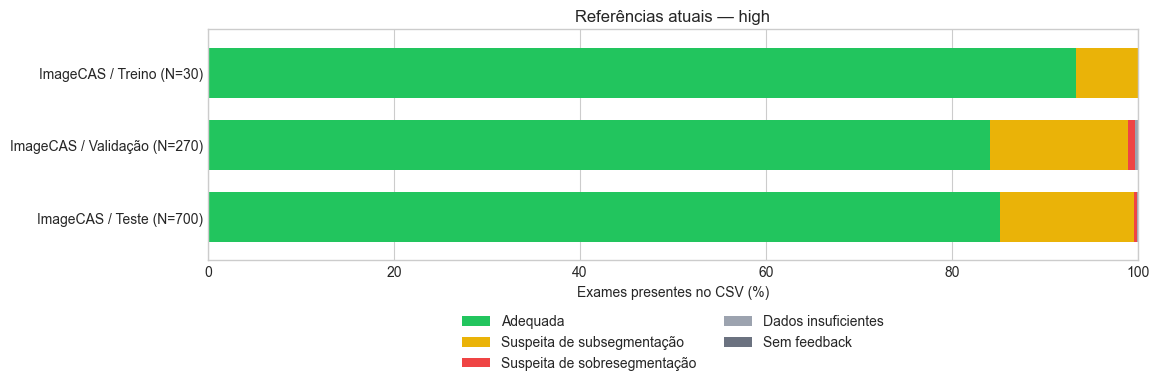

In [4]:
for resolution in ("mid", "high"):
    selected = summary.loc[
        summary["reference"].eq("Atual") & summary["resolution"].eq(resolution)
    ]
    selected_coverage = coverage.loc[
        coverage["reference"].eq("Atual") & coverage["resolution"].eq(resolution)
    ]
    show_feedback_panel(
        selected, selected_coverage, f"Referências atuais — {resolution}"
    )

## 4. Comparação complementar com ImageCAS mid histórico

Este painel usa exclusivamente os diagnósticos históricos ImageCAS mid dos runs `lower100_pad2`:
treino de 06/09/2026, validação **completa de 270 exames** e teste de 07/09/2026.
Os externos mantêm suas referências atuais, identificadas na tabela de fontes.
Esta comparação não preenche os CSVs canônicos nem permite atribuir esses diagnósticos aos sweeps mais recentes.

,reference,dataset,resolution,subset,source_path,source_run,expected_count,exam_count,missing_count,with_feedback,status
6,Atual,MM-WHS,mid,train,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,20.0,<NA>,<NA>,<NA>,Arquivo ausente
7,Atual,MM-WHS,mid,val,,,NaN,<NA>,<NA>,<NA>,Não se aplica
8,Atual,MM-WHS,mid,test,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,40.0,<NA>,<NA>,<NA>,Arquivo ausente
12,Atual,OrCaScore,mid,train,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,32.0,<NA>,<NA>,<NA>,Arquivo ausente
13,Atual,OrCaScore,mid,val,,,NaN,<NA>,<NA>,<NA>,Não se aplica
14,Atual,OrCaScore,mid,test,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,40.0,<NA>,<NA>,<NA>,Arquivo ausente
18,Histórico,ImageCAS,mid,train,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,30.0,30,0,30,Disponível
19,Histórico,ImageCAS,mid,val,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,270.0,270,0,270,Disponível
20,Histórico,ImageCAS,mid,test,/home/matheus/workspace/coronary-centerline-de...,/home/matheus/workspace/coronary-centerline-de...,700.0,700,0,700,Disponível


status                                  N      Adequada  \
reference dataset  resolution subset                      
Histórico ImageCAS mid        train    30   27 (90.00%)   
                              val     270  224 (82.96%)   
                              test    700  573 (81.86%)   

status                               Suspeita de subsegmentação  \
reference dataset  resolution subset                              
Histórico ImageCAS mid        train                  3 (10.00%)   
                              val                   40 (14.81%)   
                              test                 116 (16.57%)   

status                               Suspeita de sobresegmentação  \
reference dataset  resolution subset                                
Histórico ImageCAS mid        train                     0 (0.00%)   
                              val                       6 (2.22%)   
                              test                     10 (1.43%)   

status                               Dados insuficientes Sem feedback  
reference dataset  resolution subset                                   
Histórico ImageCAS mid        train            0 (0.00%)    0 (0.00%)  
                              val              0 (0.00%)    0 (0.00%)  
                              test             1 (0.14%)    0 (0.00%)

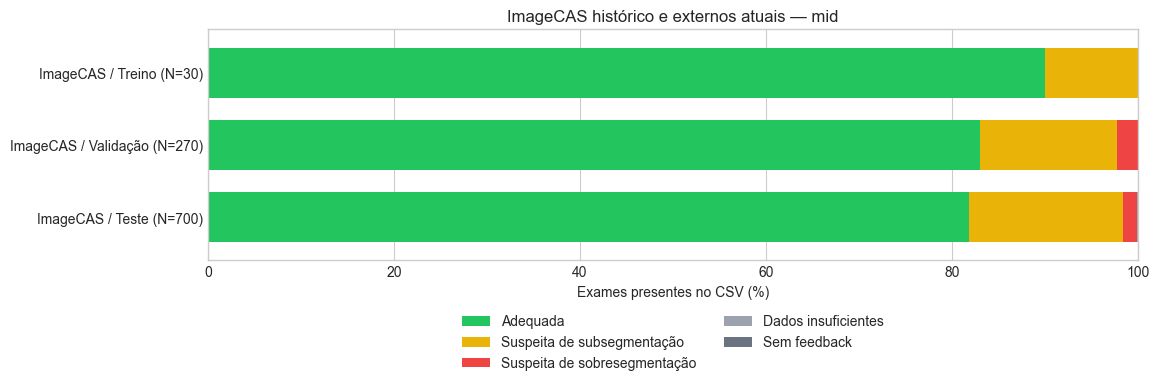

In [5]:
selected = summary.loc[
    summary["resolution"].eq("mid")
    & (summary["reference"].eq("Histórico") | summary["dataset"].ne("ImageCAS"))
]
selected_coverage = coverage.loc[
    coverage["resolution"].eq("mid")
    & (coverage["reference"].eq("Histórico") | coverage["dataset"].ne("ImageCAS"))
]
show_feedback_panel(
    selected, selected_coverage, "ImageCAS histórico e externos atuais — mid"
)

## 5. Comparação mid × high nos IDs comuns

Pareamento separado por dataset e subconjunto, somente nas referências atuais.
As transições incluem apenas IDs com a coluna de diagnóstico presente nas duas resoluções.
Um feedback vazio continua como “Sem feedback”; coluna ausente impede a comparação diagnóstica.
`common_count` informa todos os IDs comuns e `paired_diagnostics` os que permitem comparar os alertas.
Os exames exclusivos são listados, sem assumir que os conjuntos mid e high sejam idênticos.

In [6]:
paired, pairing_coverage = compare_aorta_resolutions(
    records.loc[records["reference"].eq("Atual")]
)
display(pairing_coverage)
if not paired.empty:
    comparable = paired.loc[
        paired["diagnostic_mid_available"].eq(True)
        & paired["diagnostic_high_available"].eq(True)
    ]
    for (dataset, subset), frame in comparable.groupby(
        ["dataset", "subset"], sort=False
    ):
        print(f"{dataset} / {subset}: {len(frame)} exames com diagnósticos pareados")
        display(
            pd.crosstab(frame["feedback_mid"], frame["feedback_high"]).reindex(
                index=AORTA_FEEDBACK_ORDER, columns=AORTA_FEEDBACK_ORDER, fill_value=0
            )
        )

,reference,dataset,subset,common_count,mid_only_ids,high_only_ids,paired_diagnostics
0,Atual,ImageCAS,train,30,[],[],0
1,Atual,ImageCAS,val,270,[],[],0
2,Atual,ImageCAS,test,700,[],[],0


## 6. Detalhamento por exame

Filtros independentes por referência, dataset, subconjunto, resolução e classificação.
A tabela preserva IDs, diagnósticos originais e caminho da fonte. Não há limiar de exclusão por qualidade.
A visualização é paginada em 50 registros; os filtros não modificam a base carregada.

In [7]:
PAGE_SIZE = 50


def show_exam_details(reference, dataset, subset, resolution, feedback, page):
    selected = records
    for column, value in {
        "reference": reference,
        "dataset": dataset,
        "subset": subset,
        "resolution": resolution,
        "feedback": feedback,
    }.items():
        if value != "Todos":
            selected = selected.loc[selected[column].eq(value)]
    page_count = max(1, (len(selected) + PAGE_SIZE - 1) // PAGE_SIZE)
    selected_page = min(page, page_count)
    start = (selected_page - 1) * PAGE_SIZE
    print(f"{len(selected)} registros; página {selected_page}/{page_count}")
    with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
        display(selected.iloc[start : start + PAGE_SIZE])


filters = {
    column: Dropdown(
        options=["Todos", *sorted(records[column].dropna().unique())],
        description=label,
        style={"description_width": "initial"},
    )
    for column, label in {
        "reference": "Referência",
        "dataset": "Dataset",
        "subset": "Subconjunto",
        "resolution": "Resolução",
        "feedback": "Classificação",
    }.items()
}
filters["page"] = BoundedIntText(
    value=1,
    min=1,
    max=max(1, (len(records) + PAGE_SIZE - 1) // PAGE_SIZE),
    description="Página",
)
details_output = interactive_output(show_exam_details, filters)
display(VBox([*filters.values(), details_output]))